<center><h1>Slim_Alec_HW4</h1></center>
<br>
<br>

Name: Alec Slim
<br>
Github Username: alecwslim
<br>
USC ID: 5456700424

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

import warnings, sys
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.special import expit
from scipy.stats import norm
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report)
import statsmodels.api as sm
SEED = 552

Get the AReM Data Set

In [2]:
data_dir = Path("../data/AReM")
activ = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
series = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

records = []
instances = {}
for activity in activ:
    paths = sorted((data_dir / activity).glob("dataset*.csv"),
                   key=lambda p: int(p.stem.replace("dataset", "")))
    for path in paths:
        number = int(path.stem.replace("dataset", ""))
        df = pd.read_csv(path, comment="#", header=None, sep=r"[,\s]+", engine="python", usecols=range(7))
        df.columns = ["time", *series]
        instance = len(records) + 1
        instances[instance] = df
        if activity.startswith("bending"):
            limit = 2
        else:
            limit = 3
        records.append({"Instance": instance, "activity": activity, "dataset": number,
                        "split": "test" if number <= limit else "train", "rows": len(df), "file": f"{activity}/{path.name}"})
metadata = pd.DataFrame(records).set_index("Instance")

### (b) Splitting Data

In [3]:
test_id = metadata.index[metadata["split"] == "test"]
train_id = metadata.index[metadata["split"] == "train"]

train_paths = [data_dir / file for file in metadata.loc[train_id, "file"]]
test_paths = [data_dir / file for file in metadata.loc[test_id, "file"]]
meta = metadata.reset_index(drop=True).copy()
meta['test'] = meta['split'].eq('test')
train = metadata.index.get_indexer(train_id)
test = metadata.index.get_indexer(test_id)
y = metadata['activity'].str.startswith('bending').astype(int).to_numpy()
y_multi = metadata['activity'].to_numpy()
assert len(instances) == 88 and len(train) == 69 and len(test) == 19
display(pd.crosstab(metadata['activity'], metadata['split']))
display(metadata.loc[metadata['rows'] != 480, ['activity', 'dataset', 'rows']])


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


,activity,dataset,rows
Instance,,,
51,sitting,8,479


### (c) Feature Extraction

In [4]:
statistics = ["min", "max", "mean", "median", "std", "1st quart", "3rd quart"]
def extract_features(df):
    features = {}
    for number, column in enumerate(series, start=1):
        x = df[column]
        values = [x.min(), x.max(), x.mean(), x.median(), x.std(ddof=1), x.quantile(0.25, interpolation="linear"),
                  x.quantile(0.75, interpolation="linear")]
        features.update({f"{stat}{number}": value for stat, value in zip(statistics, values)})
    return features

feature_data = pd.DataFrame.from_dict(
    {instance_id: extract_features(frame) for instance_id, frame in instances.items()},
    orient="index")
feature_data.index.name = "Instance"


X_train = feature_data.loc[train_id].copy()
X_test = feature_data.loc[test_id].copy()
y_train = metadata.loc[train_id, "activity"].copy()
y_test = metadata.loc[test_id, "activity"].copy()

display(feature_data)

rng = np.random.default_rng()
values = feature_data.to_numpy()
bootstrap_sds = []
for i in range(10000):
    indices = rng.integers(0, len(values), len(values))
    bootstrap_sds.append(values[indices].std(axis=0, ddof=1))

bounds = np.quantile(bootstrap_sds, [0.05, 0.95], axis=0)
sd_intervals = pd.DataFrame({"sample_std": values.std(axis=0, ddof=1),
                             "90%_lower": bounds[0],
                             "90%_upper": bounds[1]}, index=feature_data.columns)
sd_intervals.index.name = "feature"
display(sd_intervals)

STATS = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']
def extract(l):
    names = [f's{j+1}_part{k+1}_{stat}'
             for k in range(l) for j in range(6) for stat in STATS]
    rows = []
    for frame in instances.values():
        row = []
        for positions in np.array_split(np.arange(len(frame)), l):
            segment_features = extract_features(frame.iloc[positions])
            row.extend(segment_features.values())
        rows.append(row)
    return pd.DataFrame(rows, columns=names)

features = {l: extract(l) for l in range(1, 21)}
assert all(f.shape == (88, 42*l) and np.isfinite(f.to_numpy()).all()
           for l, f in features.items())
np.testing.assert_allclose(features[1].to_numpy(), feature_data.to_numpy())


,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,...,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


,sample_std,90%_lower,90%_upper
feature,,,
min1,9.569975,8.259694,10.760550
max1,4.394362,3.351091,5.292743
mean1,5.335718,4.726642,5.878232
median1,5.440054,4.824630,6.001469
std1,1.772153,1.571554,1.953799
1st quart1,6.153590,5.590322,6.652189
3rd quart1,5.138925,4.351275,5.837907
min2,0.000000,0.000000,0.000000
max2,5.062729,4.627610,5.404502


iv. I selected the mean, standard deviation, and median. I selected the mean to measure the overall signal level, the standard deviation to measure the variation of the signal throughout an activity, and the median to avoid extremes from impacting my measurements.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

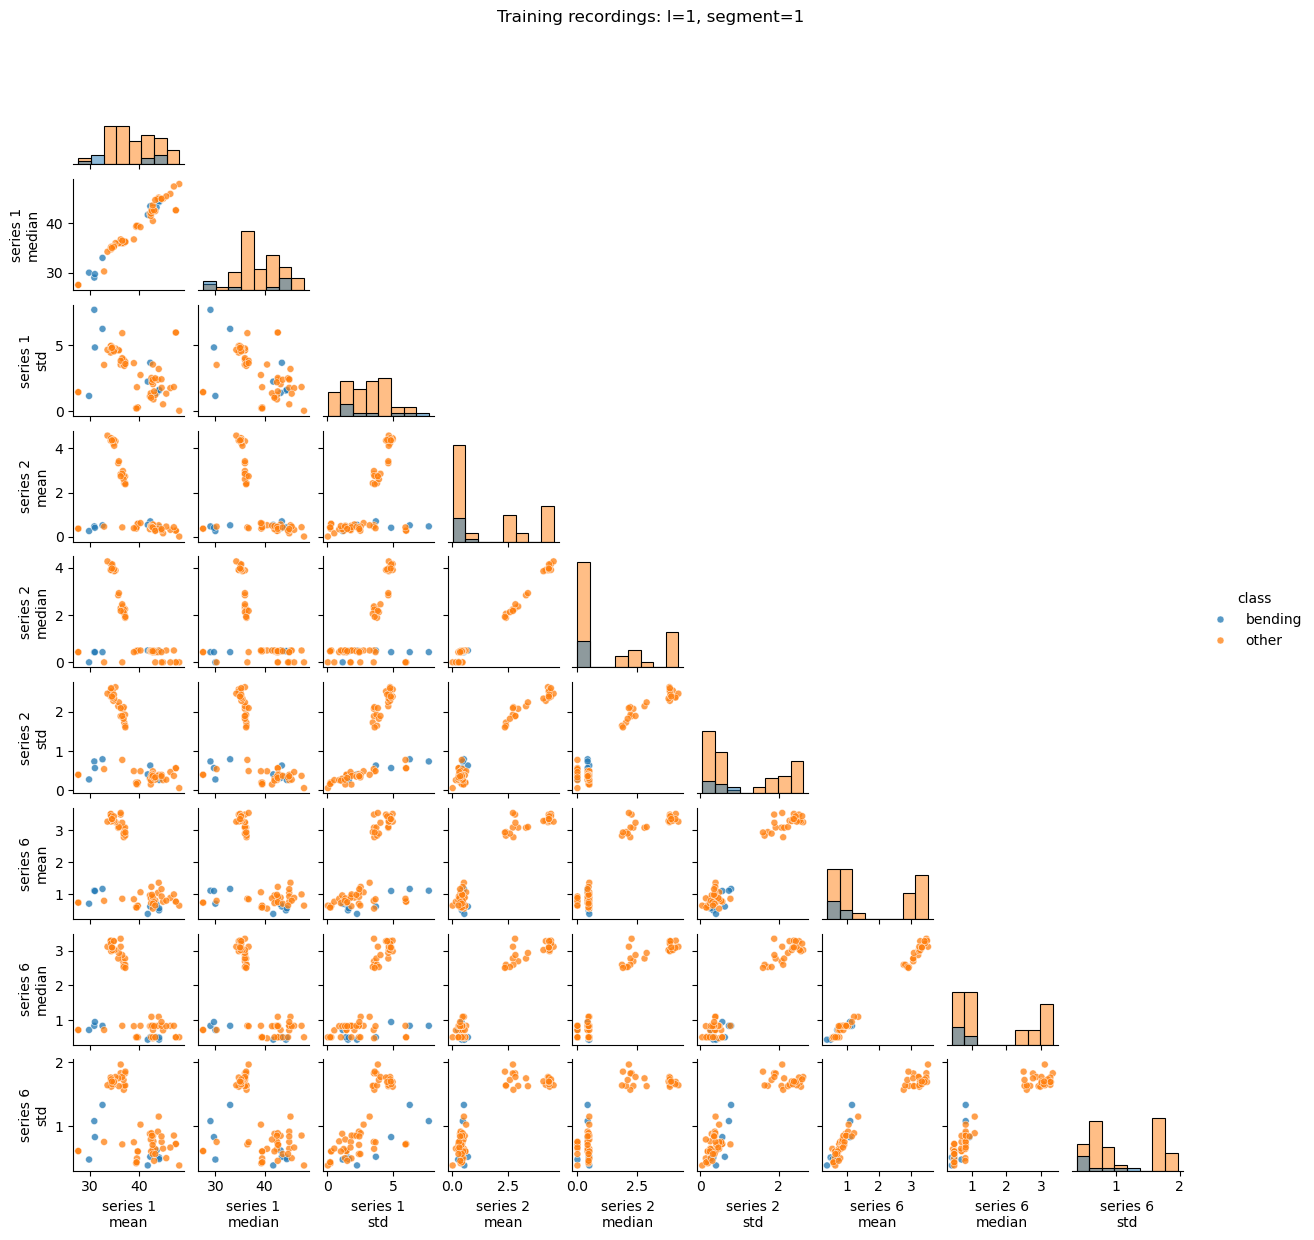

In [5]:
def scatter_features(l, part):
    cols=[f's{j}_part{part}_{s}' for j in (1,2,6) for s in ('mean','median','std')]
    frame=features[l].iloc[train][cols].copy()
    frame.columns=[f"series {c.split('_')[0][1:]}\n{c.split('_')[-1]}" for c in cols]
    frame['class']=np.where(y[train], 'bending','other')
    g=sns.pairplot(frame,hue='class',corner=True,diag_kind='hist',
                   plot_kws={'s':25,'alpha':.75},height=1.35)
    g.figure.suptitle(f'Training recordings: l={l}, segment={part}',y=1.02)
    plt.show()
scatter_features(1,1)

#### ii. Splitted Plots
The two parts of this image show the same general pattern of overlapping as seen in l=1. There is no significant increase in the visual separation of the images. Recordings of bending tend to have lower mean/median values in the variability series 2 and 6, however, many other types of activity will also fall into this area. Mean and median are very close to a diagonal line due to their high correlation. The median standardized class-mean difference is 0.734 for one segment and 0.730 for two segments, which indicates a small amount of change overall.

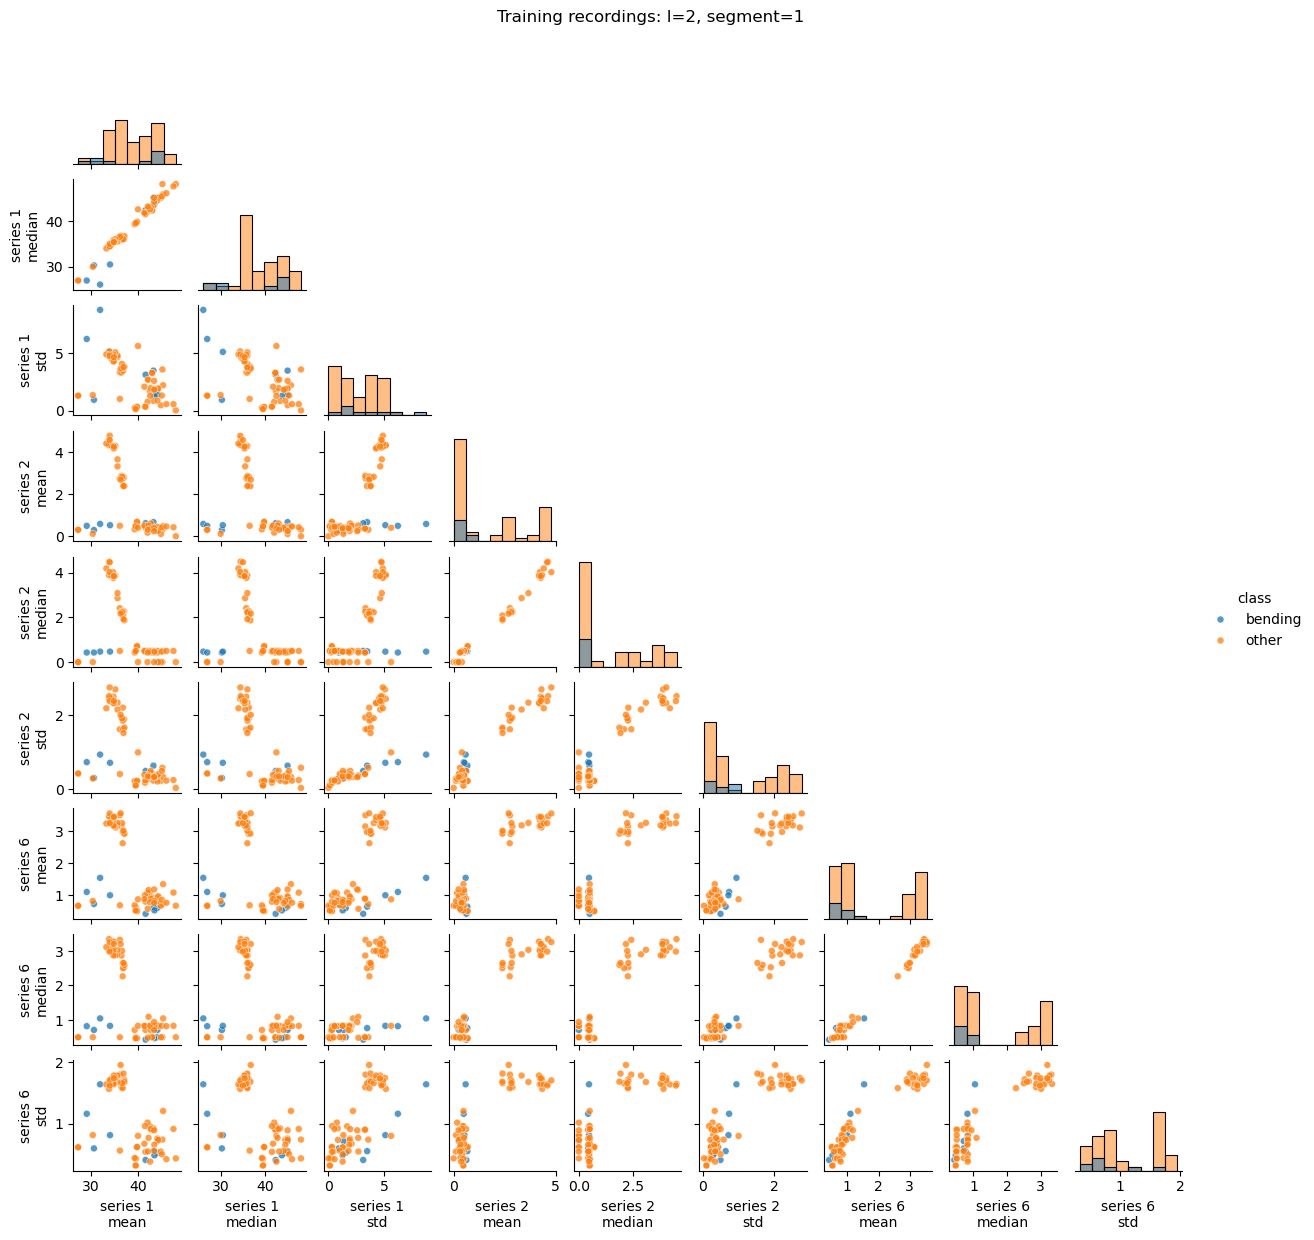

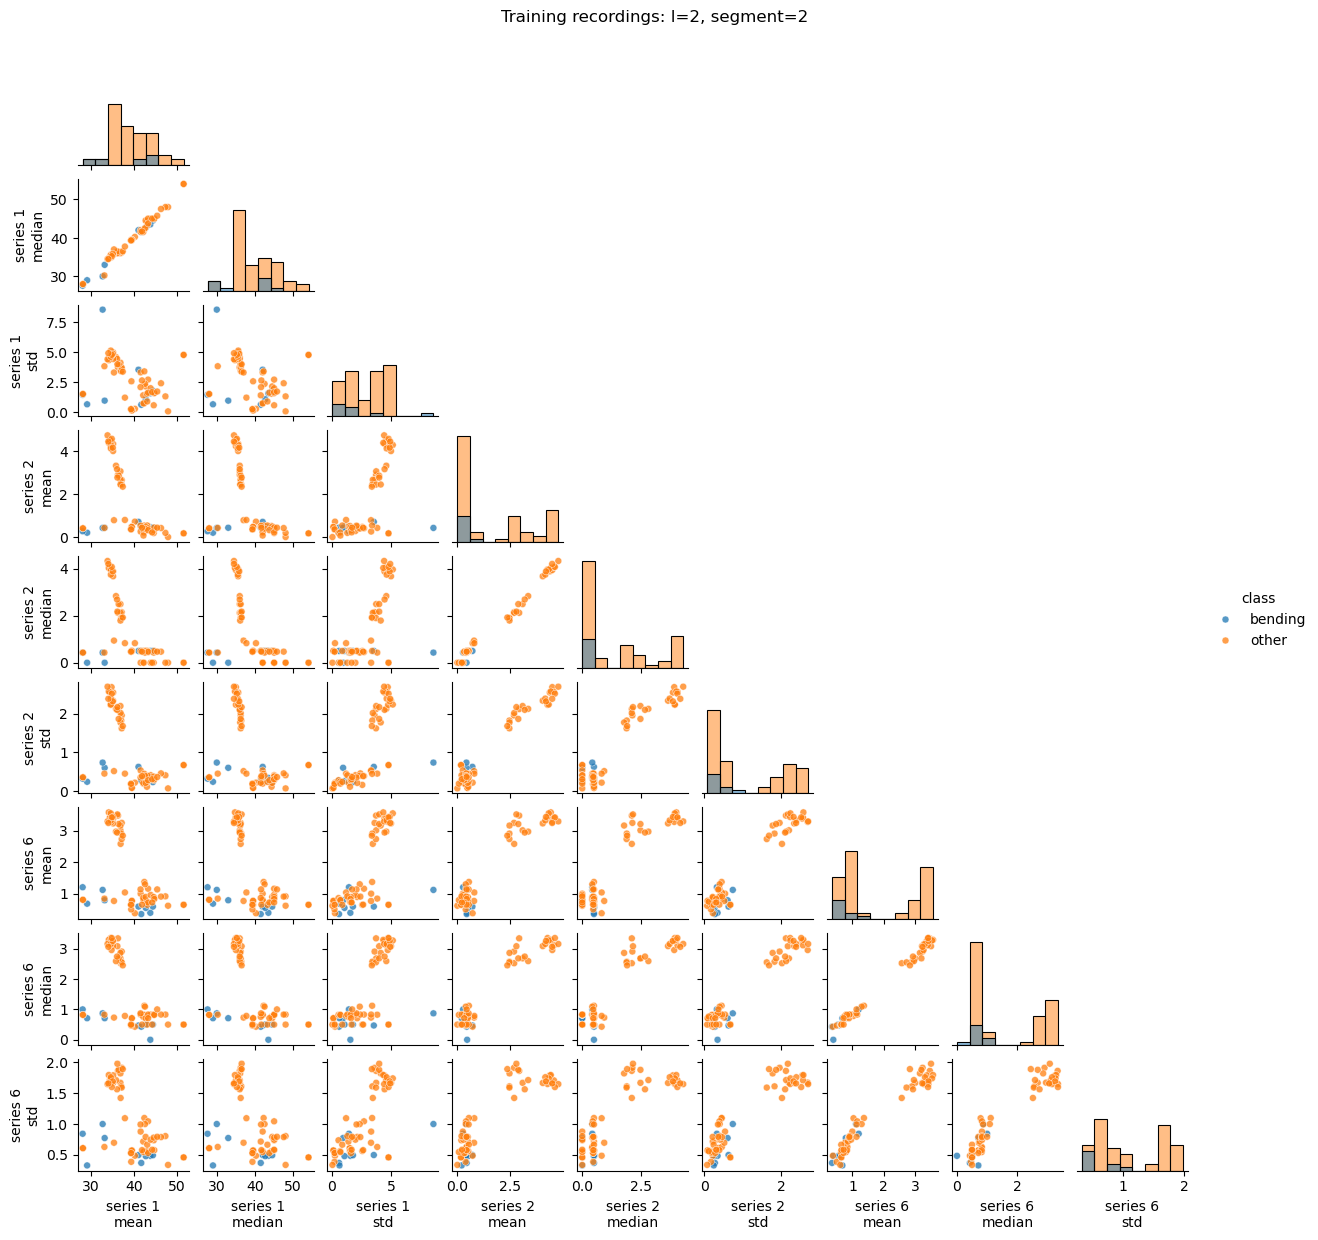

l=1: median class-mean difference = 0.734
l=2: median class-mean difference = 0.730


In [6]:
scatter_features(2,1)
scatter_features(2,2)

for l in (1,2):
    cols=[c for c in features[l] if c.split('_')[0] in ['s1','s2','s6'] and c.split('_')[-1] in ['mean','median','std']]
    f=features[l].iloc[train][cols]
    effect=(f[y[train]==1].mean()-f[y[train]==0].mean()).abs()/f.std().replace(0,np.nan)
    print(f'l={l}: median class-mean difference = {effect.median():.3f}')


#### iii. Time Series Segments

Right: Split the data into folds first. Then, apply constant removal, scaling, RFE, and logistic regression to each fold's training rows. Test the model on the validation recordings of that fold. After you have selected a final model from the 69 training recordings, fit the model on all 69 training recordings and test the model on the 19 test recordings. Segmentation and per-recording summaries are deterministic and can be safely pre-computed.

Wrong: Select predictors, standardize using all records, or tune segmentation using the test set prior to CV or treat segments/time points as separate observations and distribute the same recording across folds. All of these will result in leaking information. Stratification will approximately preserve each class's proportion and ensure that the nine bending training examples are included in every validation fold. The maximum CV accuracy is a tuning score and has selection optimism which is not an unbiased nested-CV estimate.

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
P_GRID=[1,2,3,5,10,20,30]
def plain_logit():
    return LogisticRegression(penalty=None,solver='lbfgs',max_iter=1500,tol=1e-5)
def rfe_pipeline(p):
    return Pipeline([('constant',VarianceThreshold()),('scale',StandardScaler()),
        ('select',RFE(plain_logit(),n_features_to_select=p,step=.5)),('model',plain_logit())])
# Capture solver warnings and report counts rather than silently discarding them.
solver_warnings=[]
def cv_accuracy(model,X,target):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always',ConvergenceWarning)
        scores=cross_val_score(model,X,target,cv=cv,scoring='accuracy',n_jobs=1,error_score='raise')
    solver_warnings.extend(str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning))
    return scores.mean(),scores.std(ddof=1)
rfe_rows=[]
for l in range(1,21):
    for p in P_GRID:
        mean,sd=cv_accuracy(rfe_pipeline(p),features[l].iloc[train],y[train])
        rfe_rows.append(dict(l=l,p=p,cv_accuracy=mean,cv_sd=sd))
rfe_results=pd.DataFrame(rfe_rows).sort_values(['cv_accuracy','p','l'],ascending=[False,True,True])
display(rfe_results.head(15))
best_rfe=rfe_results.iloc[0]; lr_l=int(best_rfe.l); lr_p=int(best_rfe.p)
lr=rfe_pipeline(lr_p).fit(features[lr_l].iloc[train],y[train])
print('Chosen l,p:',lr_l,lr_p,'CV accuracy:',best_rfe.cv_accuracy)


,l,p,cv_accuracy,cv_sd
2,1,3,0.985714,0.031944
10,2,5,0.985714,0.031944
124,18,20,0.971429,0.039123
137,20,10,0.970330,0.040674
1,1,2,0.957143,0.039123
9,2,3,0.957143,0.063888
23,4,3,0.957143,0.063888
37,6,3,0.957143,0.039123
66,10,5,0.957143,0.063888
81,12,10,0.957143,0.063888


Chosen l,p: 1 3 CV accuracy: 0.9857142857142858


/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.1

#### iv. Confusion Matrix

The intercept and coefficients shown above are based upon standardized selected variables. Wald p-values can be calculated only if there is a finite, well-conditioned, unpenalized maximum likelihood fit. If separation occurs or the information matrix is singular, then ordinary Wald inference cannot be relied upon; therefore, calculating a numerical pseudoinverse p-value would hide this issue. Since RFE was used as the feature selection method, p-values are descriptive and will not be used to choose features. Post-selection p-values may look valid but they do not represent confirmatory inference.

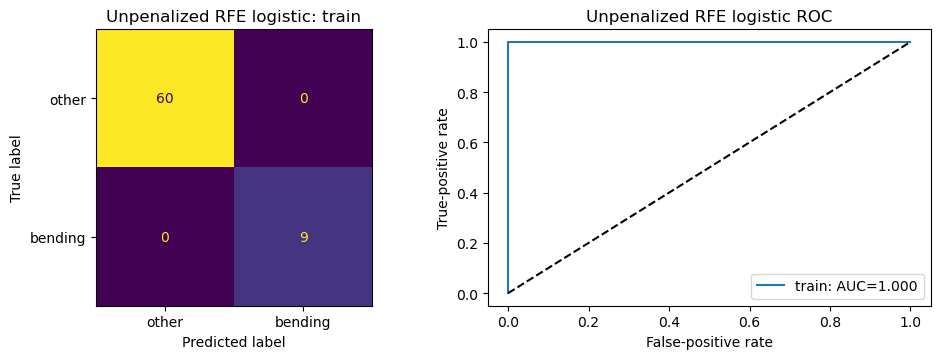

,accuracy,balanced_accuracy,AUC
train,1.0,1.0,1.0


Minimum signed training margin: 7.326271279386994
Complete separation: no finite unpenalized MLE exists; Wald p-values are undefined.


,coefficient,Wald p-value
intercept,-35.614815,NaN
s1_part1_q3,-10.405556,NaN
s5_part1_min,17.949229,NaN
s5_part1_max,22.064774,NaN


In [8]:
def binary_report(model,l,name,splits=('train','test')):
    fig,axs=plt.subplots(1,len(splits)+1,figsize=(5*(len(splits)+1),3.7))
    result={}
    for ax,label in zip(axs[:-1],splits):
        indices=train if label=='train' else test
        X=features[l].iloc[indices]; truth=y[indices]
        prob=model.predict_proba(X)[:,1]; pred=(prob>=.5).astype(int)
        ConfusionMatrixDisplay(confusion_matrix(truth,pred,labels=[0,1]),display_labels=['other','bending']).plot(ax=ax,colorbar=False)
        ax.set_title(f'{name}: {label}')
        fpr,tpr,_=roc_curve(truth,prob); auc=roc_auc_score(truth,prob)
        axs[-1].plot(fpr,tpr,label=f'{label}: AUC={auc:.3f}')
        result[label]={'accuracy':accuracy_score(truth,pred),'balanced_accuracy':balanced_accuracy_score(truth,pred),'AUC':auc}
    axs[-1].plot([0,1],[0,1],'k--');axs[-1].set(xlabel='False-positive rate',ylabel='True-positive rate',title=name+' ROC');axs[-1].legend()
    plt.tight_layout();plt.show();display(pd.DataFrame(result).T)
    return result
rfe_metrics=binary_report(lr,lr_l,'Unpenalized RFE logistic',splits=('train',))
base_names=features[lr_l].columns[lr.named_steps['constant'].get_support()]
selected_names=base_names[lr.named_steps['select'].support_]

Z=lr[:-1].transform(features[lr_l].iloc[train]); D=sm.add_constant(Z,has_constant='add')
coef=np.r_[lr.named_steps['model'].intercept_,lr.named_steps['model'].coef_.ravel()]
coef_table=pd.DataFrame({'coefficient':coef,'Wald p-value':np.nan},index=['intercept',*selected_names])
signed_margins = (2*y[train]-1) * lr.decision_function(features[lr_l].iloc[train])

print('Minimum signed training margin:', signed_margins.min())
if (signed_margins > 0).all():
    print('Complete separation: no finite unpenalized MLE exists; Wald p-values are undefined.')
else:
    with warnings.catch_warnings(record=True) as mle_warnings:
        warnings.simplefilter('always')
        try:
            mle=sm.Logit(y[train],D).fit(disp=False,maxiter=200)
            information=D.T @ ((mle.predict()*(1-mle.predict()))[:,None]*D)
            reliable=(mle.mle_retvals['converged'] and np.linalg.cond(information)<1e10
                      and max(abs(mle.params))<30 and not mle_warnings)
            if reliable:
                coef_table['MLE coefficient']=mle.params
                coef_table['Wald p-value']=mle.pvalues
            else: print('Wald p-values unavailable: separation, nonconvergence, or ill-conditioned information.')
        except Exception as e: print('Wald p-values unavailable:',type(e).__name__,str(e)[:180])
    print('Statsmodels diagnostics:', sorted({str(w.message)[:180] for w in mle_warnings}))
display(coef_table)


#### v. Test Classifier

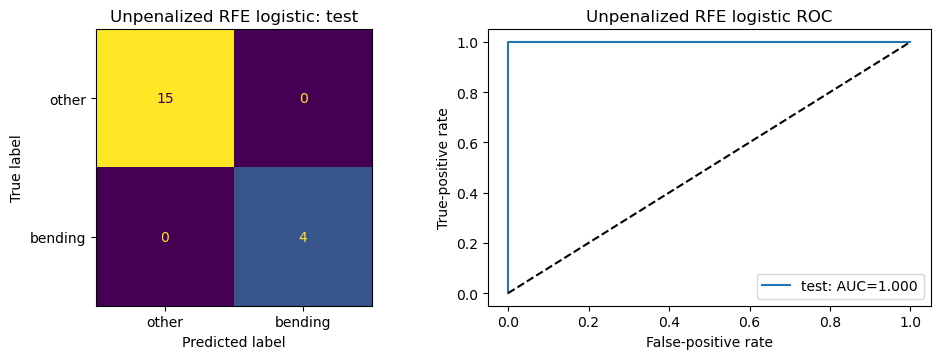

,accuracy,balanced_accuracy,AUC
test,1.0,1.0,1.0


Test accuracy = 1.000; selected CV accuracy = 0.986.


In [9]:
rfe_metrics['test']=binary_report(lr,lr_l,'Unpenalized RFE logistic',splits=('test',))['test']
print(f'Test accuracy = {rfe_metrics["test"]["accuracy"]:.3f}; selected CV accuracy = {best_rfe.cv_accuracy:.3f}.')

#### vi. Separation

The complete separation of all bending recordings from all other training recordings is what happens when a predictor combination can completely separate the two types of recordings. When this happens, as you increase the coefficient for the predictor combination, the unpenalized likelihood will continue to increase without bound; therefore, there is no finite maximum likelihood estimate and the ordinary Wald p-value cannot be calculated.

Observed Result: The selected model has three predictors from unsplit recordings (`l=1`, `p=3`) which are `s1_part1_q3`, `s5_part1_min`, and `s5_part1_max`. This model perfectly classifies the training recordings. The positive minimum signed margin shown in part (iv) confirms that this model exhibits strict separation and thus exhibits the instability described in the assignment. The coefficients shown are finite solver stopping values and not a finite MLE; the p-values have been intentionally left undefined. L1 regularization in part (b) limits the growth of the coefficients.

#### vii. Imbalance

The training data contains 9 bending and 60 other recordings. The test data contains 4 bending and 15 other recordings. Accuracy may mask low recall in the minority class. I will use all of the bending cases from the training data and randomly select an equal number of control cases from the training data. The feature representation will remain the same as that which was selected during the training-CV process. I will then re-estimate the logistic slopes and adjust the sample intercept to reflect the prevalence of the population in the training data:


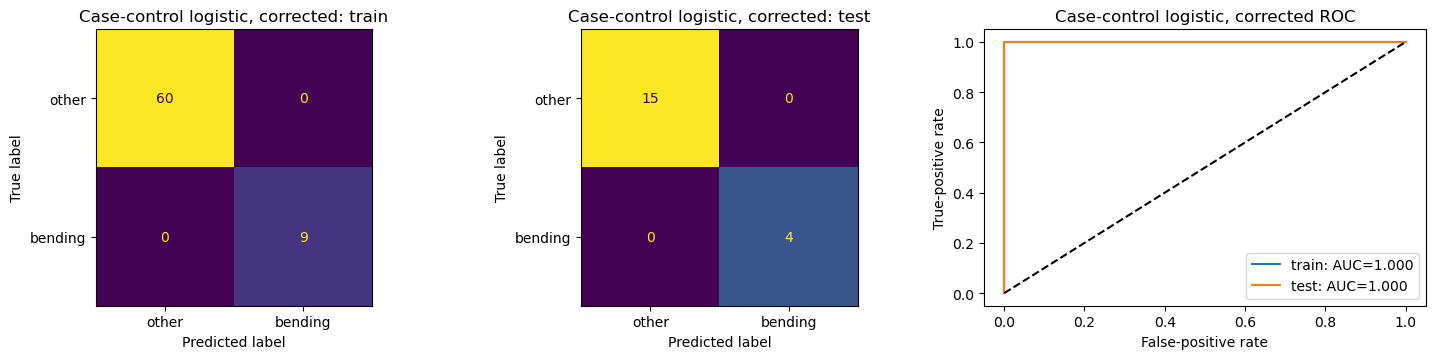

,accuracy,balanced_accuracy,AUC
train,1.0,1.0,1.0
test,1.0,1.0,1.0


In [10]:
rng=np.random.default_rng(SEED)
cases=train[y[train]==1]; controls=rng.choice(train[y[train]==0],size=len(cases),replace=False)
sampled=np.r_[cases,controls]
copy=clone(lr)
copy.set_params(model=LogisticRegression(C=1e6,solver='lbfgs',max_iter=3000))
copy.steps=lr.steps[:-1]+[('model',LogisticRegression(C=1e6,max_iter=3000))]
copy.named_steps['model'].fit(lr[:-1].transform(features[lr_l].iloc[sampled]),y[sampled])
pi=y[train].mean(); pi_s=y[sampled].mean()
shift=np.log(pi/(1-pi))-np.log(pi_s/(1-pi_s))
copy.named_steps['model'].intercept_+=shift
cc_metrics=binary_report(copy,lr_l,'Case-control logistic, corrected')

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Binary L1 l=1 complete
Binary L1 l=2 complete
Binary L1 l=3 complete
Binary L1 l=4 complete
Binary L1 l=5 complete
Binary L1 l=6 complete
Binary L1 l=7 complete
Binary L1 l=8 complete
Binary L1 l=9 complete
Binary L1 l=10 complete
Binary L1 l=11 complete
Binary L1 l=12 complete
Binary L1 l=13 complete
Binary L1 l=14 complete
Binary L1 l=15 complete
Binary L1 l=16 complete
Binary L1 l=17 complete
Binary L1 l=18 complete
Binary L1 l=19 complete
Binary L1 l=20 complete


,l,C,cv_accuracy,cv_sd
42,11,1.0,0.985714,0.031944
46,12,1.0,0.985714,0.031944
47,12,10.0,0.985714,0.031944
75,19,10.0,0.985714,0.031944
2,1,1.0,0.971429,0.039123
50,13,1.0,0.971429,0.039123
70,18,1.0,0.971429,0.039123
43,11,10.0,0.971429,0.039123
79,20,10.0,0.971429,0.039123
6,2,1.0,0.957143,0.039123


/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


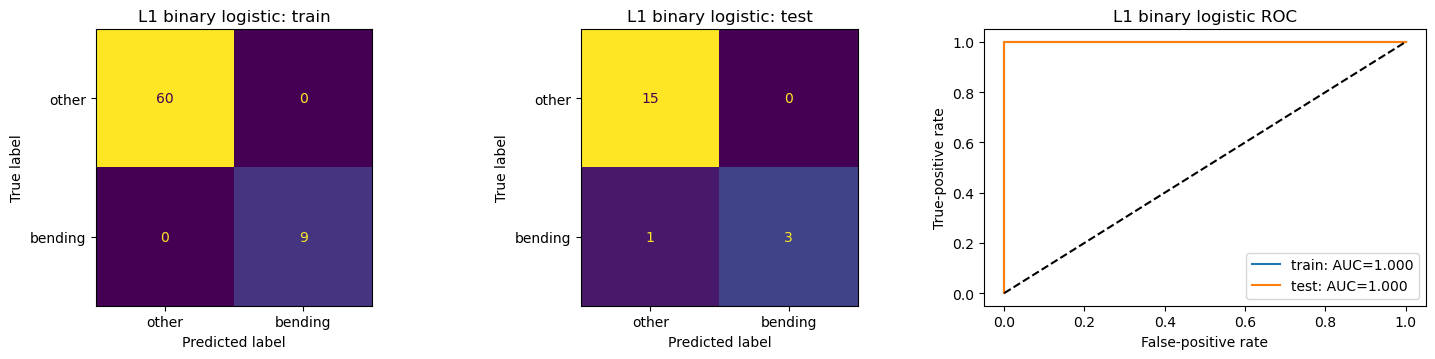

,accuracy,balanced_accuracy,AUC
train,1.000000,1.000,1.0
test,0.947368,0.875,1.0


In [ ]:
C_GRID=[.01,.1,1.,10.]
def l1_pipeline(C,multi=False):
    return Pipeline([('constant',VarianceThreshold()),('scale',StandardScaler()),
        ('model',LogisticRegression(penalty='l1',C=C,solver='saga' if multi else 'liblinear',
                  max_iter=4000,tol=1e-3,random_state=SEED))])
def tune_l1(target,multi=False):
    rows=[]
    for l in range(1,21):
        for C in C_GRID:
            mean,sd=cv_accuracy(l1_pipeline(C,multi),features[l].iloc[train],target[train])
            rows.append(dict(l=l,C=C,cv_accuracy=mean,cv_sd=sd))
    return pd.DataFrame(rows).sort_values(['cv_accuracy','C','l'],ascending=[False,True,True])
l1_results=tune_l1(y)
display(l1_results.head(12))
best_l1=l1_results.iloc[0]; l1_l=int(best_l1.l)
l1=l1_pipeline(float(best_l1.C)).fit(features[l1_l].iloc[train],y[train])
l1_metrics=binary_report(l1,l1_l,'L1 binary logistic')


#### ii. Comparison

The two models produced an average of **98.57% five-fold cross-validation accuracy** using the training data. RFE chose `l=1` and three features; L1 chose `l=11`, `C=1` and kept ten non-zero coefficients. In the hold-out set, RFE correctly identified 19/19 recordings, while L1 correctly identified 18/19 (94.74%). Both had a test AUC of 1.0, which means that both models ordered all cases correctly according to this split; however, one L1 prediction was on the wrong side of the 0.5 threshold, so RFE had a higher observed test accuracy than L1. The CV criteria were the same for both models. Since there were only 19 test recordings, each single error would result in about a 5.3% difference in accuracy. An advantage of L1 is that it is easier to implement than RFE. With L1, you can do both shrinkage and feature selection in a single fit. Also, L1 restricts how large coefficients can grow when there is separation.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

A multiclass confusion matrix shows actual classes in rows and predicted classes in columns. To create an ROC for multiclass, you must consider each class as positive and all other classes as negative. You will then be able to generate a one-versus-rest curve based on the probability of each class. Macro AUC treats each class equally; micro AUC combines all of the class indicator entries. There is no single ROC curve that is inherent to multiclass classification.[scikit-learn's multiclass ROC example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html).

Multiclass L1 l=1 complete
Multiclass L1 l=2 complete
Multiclass L1 l=3 complete
Multiclass L1 l=4 complete
Multiclass L1 l=5 complete
Multiclass L1 l=6 complete
Multiclass L1 l=7 complete
Multiclass L1 l=8 complete
Multiclass L1 l=9 complete
Multiclass L1 l=10 complete
Multiclass L1 l=11 complete
Multiclass L1 l=12 complete
Multiclass L1 l=13 complete
Multiclass L1 l=14 complete
Multiclass L1 l=15 complete
Multiclass L1 l=16 complete
Multiclass L1 l=17 complete
Multiclass L1 l=18 complete
Multiclass L1 l=19 complete
Multiclass L1 l=20 complete


,l,C,cv_accuracy,cv_sd
3,1,10.0,0.913187,0.031420
7,2,10.0,0.900000,0.081441
2,1,1.0,0.884615,0.095247
6,2,1.0,0.871429,0.105946
11,3,10.0,0.870330,0.029487
14,4,1.0,0.857143,0.087482
15,4,10.0,0.857143,0.087482
71,18,10.0,0.856044,0.048588
19,5,10.0,0.854945,0.050746
70,18,1.0,0.841758,0.057810


/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/DSCI550/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


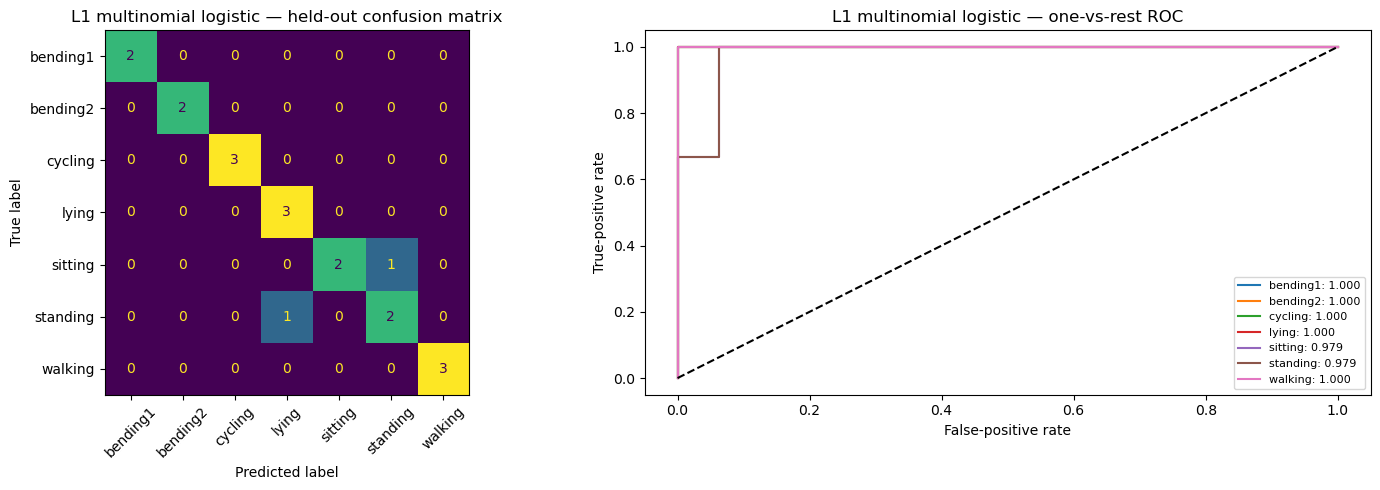

              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.75      1.00      0.86         3
     sitting       1.00      0.67      0.80         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.90      0.90        19
weighted avg       0.91      0.89      0.89        19



test_accuracy    0.894737
test_error       0.105263
macro_OVR_AUC    0.994048
micro_AUC        0.996768
dtype: float64

In [12]:
multi_results=tune_l1(y_multi,multi=True)
display(multi_results.head(12))
best_multi=multi_results.iloc[0]; multi_l=int(best_multi.l)
multi=l1_pipeline(float(best_multi.C),True).fit(features[multi_l].iloc[train],y_multi[train])
def multiclass_report(model,l,name):
    X=features[l].iloc[test]; truth=y_multi[test]
    classes=model.classes_; pred=model.predict(X); prob=model.predict_proba(X)
    Y=label_binarize(truth,classes=classes)
    fig,axs=plt.subplots(1,2,figsize=(15,5))
    ConfusionMatrixDisplay(confusion_matrix(truth,pred,labels=classes),display_labels=classes).plot(ax=axs[0],xticks_rotation=45,colorbar=False)
    axs[0].set_title(name+' — held-out confusion matrix')
    aucs={}
    for j,label in enumerate(classes):
        fpr,tpr,_=roc_curve(Y[:,j],prob[:,j]); aucs[label]=roc_auc_score(Y[:,j],prob[:,j])
        axs[1].plot(fpr,tpr,label=f'{label}: {aucs[label]:.3f}')
    axs[1].plot([0,1],[0,1],'k--');axs[1].legend(fontsize=8)
    axs[1].set(xlabel='False-positive rate',ylabel='True-positive rate',title=name+' — one-vs-rest ROC')
    plt.tight_layout();plt.show()
    print(classification_report(truth,pred,labels=classes,zero_division=0))
    result={'test_accuracy':accuracy_score(truth,pred),'test_error':1-accuracy_score(truth,pred),
        'macro_OVR_AUC':np.mean(list(aucs.values())),
        'micro_AUC':roc_auc_score(Y.ravel(),prob.ravel())}
    display(pd.Series(result));return result
multi_metrics=multiclass_report(multi,multi_l,'L1 multinomial logistic')


#### ii. Naive Bayes

I select l and a small smoothing grid based on training CV only. GaussianNB uses Gaussian density functions to model continuous features, which are specific to each class. MultinomialNB uses non-negative feature mass/count values to model data however, multinomial likelihood is less natural than Gaussian likelihood for continuous RSS summaries, but the comparison is still valid as an empirical classifier. Both models use empirical training class probabilities. Since the raw extracted features are non-negative, no centering or test-dependent shifts are required for MultinomialNB.

,l,smoothing,cv_accuracy,cv_sd
0,1,1.000000e-11,0.869231,0.060614
1,1,1.000000e-09,0.869231,0.060614
2,1,1.000000e-07,0.869231,0.093681
3,2,1.000000e-11,0.854945,0.071597
4,2,1.000000e-09,0.854945,0.071597
5,2,1.000000e-07,0.854945,0.071597
8,3,1.000000e-07,0.765934,0.114637
6,3,1.000000e-11,0.750549,0.122529


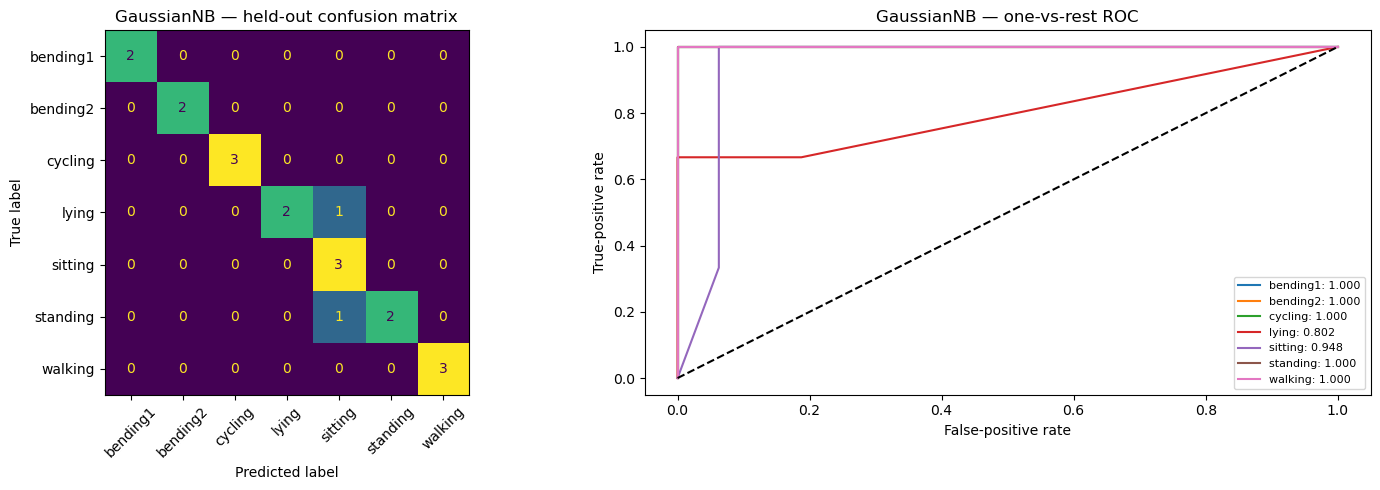

              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.60      1.00      0.75         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.94      0.90      0.91        19
weighted avg       0.94      0.89      0.90        19



test_accuracy    0.894737
test_error       0.105263
macro_OVR_AUC    0.964286
micro_AUC        0.959834
dtype: float64

,l,smoothing,cv_accuracy,cv_sd
0,1,0.1,0.854945,0.151603
3,2,0.1,0.826374,0.107712
4,2,1.0,0.826374,0.107712
13,5,1.0,0.826374,0.037387
15,6,0.1,0.826374,0.037387
21,8,0.1,0.826374,0.037387
30,11,0.1,0.826374,0.080621
39,14,0.1,0.826374,0.037387


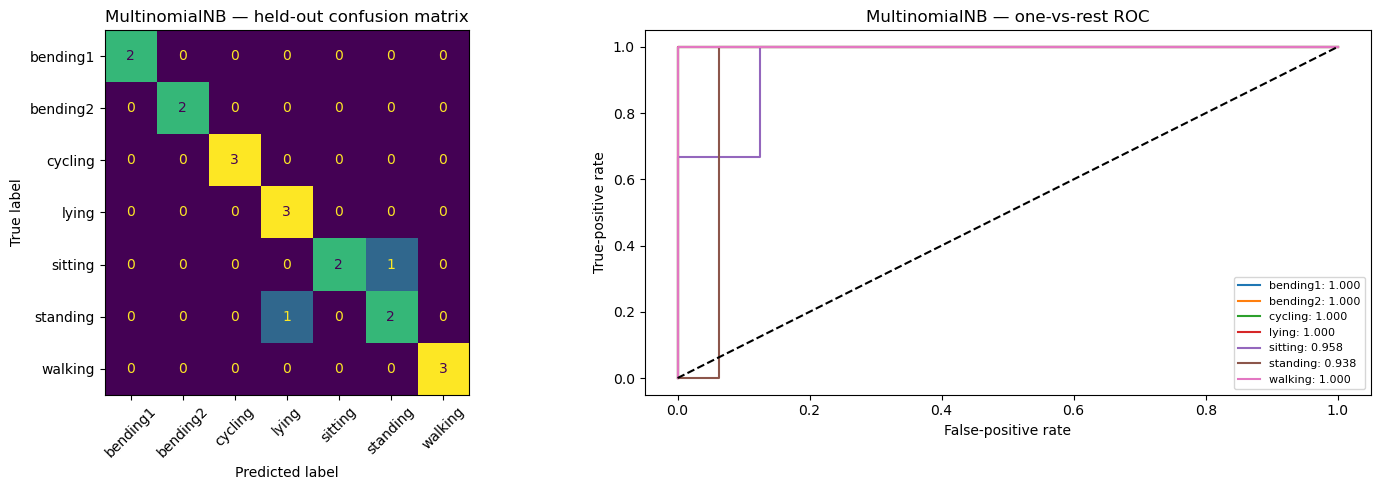

              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.75      1.00      0.86         3
     sitting       1.00      0.67      0.80         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.90      0.90        19
weighted avg       0.91      0.89      0.89        19



test_accuracy    0.894737
test_error       0.105263
macro_OVR_AUC    0.985119
micro_AUC        0.991228
dtype: float64

In [13]:
nb_best={};nb_results={}
for name,grid in [('GaussianNB',[1e-11,1e-9,1e-7]),('MultinomialNB',[.1,1.,10.])]:
    rows=[]
    for l in range(1,21):
        for smooth in grid:
            model=GaussianNB(var_smoothing=smooth) if name=='GaussianNB' else MultinomialNB(alpha=smooth)
            mean,sd=cv_accuracy(model,features[l].iloc[train],y_multi[train])
            rows.append(dict(l=l,smoothing=smooth,cv_accuracy=mean,cv_sd=sd))
    results=pd.DataFrame(rows).sort_values(['cv_accuracy','l','smoothing'],ascending=[False,True,True])
    nb_results[name]=results;best=results.iloc[0];l=int(best.l)
    model=GaussianNB(var_smoothing=best.smoothing) if name=='GaussianNB' else MultinomialNB(alpha=best.smoothing)
    model.fit(features[l].iloc[train],y_multi[train])
    display(results.head(8))
    nb_best[name]={'l':l,'cv_accuracy':best.cv_accuracy,**multiclass_report(model,l,name)}


#### ii. Comparison

The three models correctly classified 17/19 of the held out recordings. Therefore, we cannot use the held out classification error to differentiate between the models.

The training-cross-validation accuracy was 91.32% for L1 multinomial logistic regression, 86.92% for GaussianNB, and 85.49% for MultinomialNB. Based upon this comparison of training only, I would select L1 multinomial logistic regression. This model selected `l=1`, `C=10` and produced a macro one-versus-rest test AUC of approximately 0.9940.

## 3. ISLR 4.8.3


$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$
$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x+
\log\pi_k-\log\sigma_k-\frac{\mu_k^2}{2\sigma_k^2}.$$
The decision boundaries between pairs of classes ($k$, $j$) are found when $\delta_k(x) - \delta_j(x) = 0$. Since the coefficient of $x^2$ is $(1/2\sigma_j^2) - (1/2\sigma_k^2)$, it is usually non-zero since the variance is typically different. Therefore, pairwise discriminant comparisons are quadratic and can produce at least two boundary points. If all of the variances are equal, then the quadratic term will be removed and we will have LDA's linear rule.

## 4. ISLR 4.8.7


$$P(\mathrm{yes}\mid4)=\frac{0.8\exp[-(4-10)^2/72]}{0.8\exp[-(4-10)^2/72]+0.2\exp[-4^2/72]}.$$
$$\log(0.8/0.2)-\frac{(4-10)^2-(4-0)^2}{72}=\log4-\frac{20}{72}.$$

This equation results to **0.751852**, or **75.19%**. The company is predicted to issue a dividend at a 0.5 decision threshold.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9